# Phase 3 — Quantization: Keras → LiteRT (.tflite)

**Gate ("Done when")**: `model_int8.tflite` whose test accuracy drops **< 1 pp** vs the Keras
model, with size and latency rows added to the efficiency table.

We produce three conversions of the promoted `model.keras` and evaluate each on the SAME
held-out test split via the TFLite interpreter:

| file | weights | activations | expected size |
|---|---|---|---|
| `model_fp32.tflite` | float32 | float32 | ~= Keras |
| `model_dynamic.tflite` | int8 | float32 (dyn.) | ~4x smaller |
| `model_int8.tflite` | int8 | int8 | ~4x smaller, fastest on ARM |

Full-int8 needs a **representative dataset** (a few hundred real training batches) so the
converter can calibrate activation ranges. I/O stays float32 — the Android code keeps
feeding normalized [0,1] floats; quantization is internal.

In [1]:
import sys, pathlib, json
sys.path.append(str(pathlib.Path.cwd().parent))

import numpy as np
import tensorflow as tf

from src.data import get_datasets

ARTIFACTS = pathlib.Path.cwd().parent / 'artifacts'
ds_train, ds_val, ds_test, info = get_datasets()

model = tf.keras.models.load_model(ARTIFACTS / 'model.keras')
chosen = json.load(open(ARTIFACTS / 'chosen_model.json'))
print('quantizing variant:', chosen['chosen_variant'],
      '| keras test acc:', chosen['acc'])

quantizing variant: baseline | keras test acc: 0.9436936936936937


## 1. Three conversions

In [2]:
def representative_dataset():
    # ~300 batches of REAL preprocessed training images for calibration.
    # Must go through the exact same pipeline as training data.
    for images, _ in ds_train.take(300):
        for img in images[:4]:   # a few per batch is plenty (~1200 samples)
            yield [tf.expand_dims(img, 0)]

# (a) plain float32
conv = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_fp32 = conv.convert()

# (b) dynamic-range: int8 weights, float activations
conv = tf.lite.TFLiteConverter.from_keras_model(model)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_dyn = conv.convert()

# (c) full int8 weights+activations, float32 I/O
conv = tf.lite.TFLiteConverter.from_keras_model(model)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
conv.representative_dataset = representative_dataset
conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
tflite_int8 = conv.convert()

blobs = {'model_fp32.tflite': tflite_fp32,
         'model_dynamic.tflite': tflite_dyn,
         'model_int8.tflite': tflite_int8}
for name, blob in blobs.items():
    (ARTIFACTS / name).write_bytes(blob)
    print(f"{name:22s} {len(blob)/1024:8.1f} KB")

INFO:tensorflow:Assets written to: <TEMP>\tmpn438oeam\assets


INFO:tensorflow:Assets written to: <TEMP>\tmpn438oeam\assets


Saved artifact at '<TEMP>\tmpn438oeam'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name='input_layer_3')
Output Type:
  TensorSpec(shape=(None, 26), dtype=tf.float32, name=None)
Captures:
  1845217759632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217760592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217761552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217761168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217760400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217761744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217762704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217762512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217762128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217763280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217763664: TensorSpec(shape=

INFO:tensorflow:Assets written to: <TEMP>\tmp1eo8cl4m\assets


Saved artifact at '<TEMP>\tmp1eo8cl4m'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name='input_layer_3')
Output Type:
  TensorSpec(shape=(None, 26), dtype=tf.float32, name=None)
Captures:
  1845217759632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217760592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217761552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217761168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217760400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217761744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217762704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217762512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217762128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217763280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217763664: TensorSpec(shape=

INFO:tensorflow:Assets written to: <TEMP>\tmpmngznykd\assets


Saved artifact at '<TEMP>\tmpmngznykd'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name='input_layer_3')
Output Type:
  TensorSpec(shape=(None, 26), dtype=tf.float32, name=None)
Captures:
  1845217759632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217760592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217761552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217761168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217760400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217761744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217762704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217762512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217762128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217763280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1845217763664: TensorSpec(shape=

.venv\Lib\site-packages\tensorflow\lite\python\convert.py:854: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


model_fp32.tflite         443.9 KB
model_dynamic.tflite      120.1 KB
model_int8.tflite         125.0 KB


## 2. Evaluate each .tflite on the test split
The TFLite interpreter runs one image at a time (like on the phone).
Evaluating 8,880 images x 3 models takes a couple of minutes on CPU.

In [3]:
import time

y_true = np.concatenate([y.numpy() for _, y in ds_test], axis=0)
x_test = np.concatenate([x.numpy() for x, _ in ds_test], axis=0)
print('test tensors:', x_test.shape, y_true.shape)

def eval_tflite(path):
    interp = tf.lite.Interpreter(model_path=str(path))
    interp.allocate_tensors()
    inp = interp.get_input_details()[0]
    out = interp.get_output_details()[0]
    preds = np.empty(len(x_test), dtype=np.int64)
    t0 = time.perf_counter()
    for i, x in enumerate(x_test):
        interp.set_tensor(inp['index'], x[None].astype(inp['dtype']))
        interp.invoke()
        preds[i] = interp.get_tensor(out['index']).argmax()
    ms = (time.perf_counter() - t0) / len(x_test) * 1000
    return float((preds == y_true).mean()), ms

results = {}
for name in blobs:
    acc, ms = eval_tflite(ARTIFACTS / name)
    results[name] = {'acc': acc, 'ms_per_img': ms,
                     'size_kb': (ARTIFACTS / name).stat().st_size / 1024}
    print(f"{name:22s} acc={acc:.4f}  {ms:.3f} ms/img  "
          f"{results[name]['size_kb']:.1f} KB")

test tensors: (8880, 28, 28, 1) (8880,)


.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


model_fp32.tflite      acc=0.9437  0.223 ms/img  443.9 KB
model_dynamic.tflite   acc=0.9447  0.199 ms/img  120.1 KB
model_int8.tflite      acc=0.9441  0.240 ms/img  125.0 KB


## 3. Accuracy-drop check (the gate)
Full-int8 must stay within **1 percentage point** of the Keras float model.
Typical result for this size of CNN: drop of 0.000-0.003.

In [4]:
keras_acc = chosen['acc']
drop = keras_acc - results['model_int8.tflite']['acc']
print(f"keras acc           : {keras_acc:.4f}")
print(f"int8 tflite acc     : {results['model_int8.tflite']['acc']:.4f}")
print(f"drop                : {drop*100:.2f} pp")
assert drop < 0.01, "int8 accuracy drop exceeds 1 pp — investigate before Phase 5!"
print("GATE PASSED")

keras acc           : 0.9437
int8 tflite acc     : 0.9441
drop                : -0.05 pp
GATE PASSED


## 4. Extend the efficiency table (Phase 2 table + tflite rows)

In [5]:
import pandas as pd

eff = pd.read_json(ARTIFACTS / 'efficiency_study.json')
rows = []
for name, r in results.items():
    rows.append({'variant': name.replace('.tflite',''), 'params': None,
                 'size_kb': round(r['size_kb'], 1), 'test_acc': round(r['acc'], 4),
                 'macro_f1': None, 'cpu_latency_ms': round(r['ms_per_img'], 3)})
eff_full = pd.concat([eff, pd.DataFrame(rows)], ignore_index=True)
print(eff_full.to_string(index=False))
eff_full.to_json(ARTIFACTS / 'efficiency_study.json', orient='records', indent=2)

# Note for the report: x86 interpreter latency is NOT phone latency — int8 often
# looks slower than fp32 on a desktop CPU because the x86 kernels are unoptimized;
# the real speedup shows on ARM. Cite size + accuracy here, measure latency on
# device in Phase 8.

      variant params  size_kb  test_acc macro_f1  cpu_latency_ms
     baseline 113210   1395.7    0.9437   0.9438           2.427
    separable  32154    447.9    0.9340   0.9338           1.860
   model_fp32   None    443.9    0.9437     None           0.223
model_dynamic   None    120.1    0.9447     None           0.199
   model_int8   None    125.0    0.9441     None           0.240


## 5. Sanity: int8 model on a handful of test images
Quick visual confirmation that predictions make sense before this file ships to Android.

.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


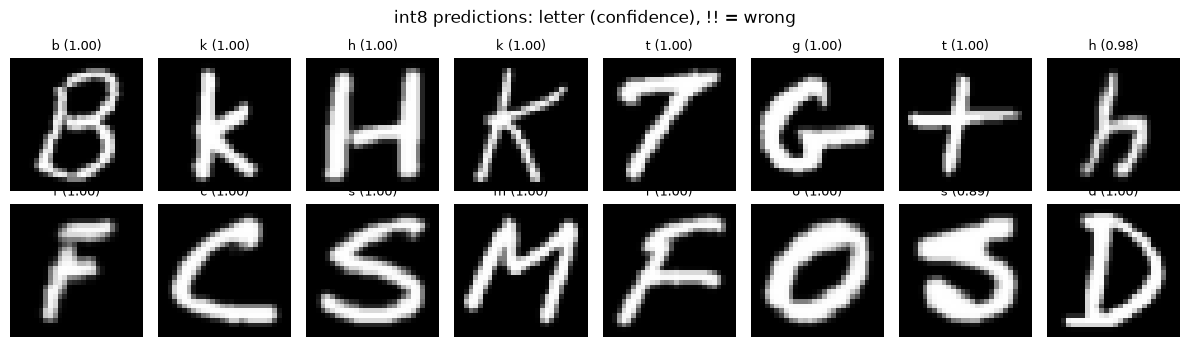

In [6]:
import string, matplotlib.pyplot as plt
letters = string.ascii_lowercase

interp = tf.lite.Interpreter(model_path=str(ARTIFACTS / 'model_int8.tflite'))
interp.allocate_tensors()
inp, out = interp.get_input_details()[0], interp.get_output_details()[0]

fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
idx = np.random.default_rng(0).choice(len(x_test), 16, replace=False)
for ax, i in zip(axes.flat, idx):
    interp.set_tensor(inp['index'], x_test[i][None].astype(inp['dtype']))
    interp.invoke()
    p = interp.get_tensor(out['index'])[0]
    pred = p.argmax()
    ok = '' if pred == y_true[i] else ' !!'
    ax.imshow(x_test[i].squeeze(), cmap='gray')
    ax.set_title(f"{letters[pred]} ({p.max():.2f}){ok}", fontsize=9)
    ax.axis('off')
plt.suptitle('int8 predictions: letter (confidence), !! = wrong')
plt.tight_layout(); plt.show()

## Gate checklist (Phase 3 "Done when")
- [X] Three .tflite files in `ml/artifacts/`, sizes follow ~4x rule
- [X] int8 accuracy drop < 1 pp (assertion passed)
- [X] Efficiency table extended and saved
- [X] Spot-check predictions look sane
- [X] `git add -A && git commit -m "Phase 3: tflite conversion + int8 quantization"`

**Ship list for Phase 5 (Android):** `model_int8.tflite` + `labels.txt` go into
`android/app/src/main/assets/`.